<img style="float: left; margin: 30px 15px 15px 15px;" src="https://oci02.img.iteso.mx/Identidades-De-Instancia/ITESO/Logos%20ITESO/Logo-ITESO-Principal.jpg" width="400" height="600" /> 
    
    
## <font color='navy'> Tarea 5. Regresión Lineal: Ingreso mensual en México (ENOE 2025-T1)
    
### <font color='navy'> Análisis Estadístico Multivariado

### <font color='navy'> Parte 1. Unión de las tablas COE1 y COE2. Limpieza y selección de variables (objetivo e independientes).

La **Encuesta Nacional de Ocupación y Empleo (ENOE)** del INEGI aplica el *Cuestionario de Ocupación y Empleo* (versión ampliada) a la población de 12 años y más. Por su tamaño, el cuestionario se publica dividido en dos tablas:

| **Tabla** | **Contenido** |
|-----------|---------------|
| **COE1** | Preguntas 1 a 5: condición de actividad, características del empleo (sindicato, contrato, prestaciones, tamaño de empresa, antigüedad) y jornada de trabajo. |
| **COE2** | Preguntas 6 a 11: ingresos (periodicidad y monto), segundo trabajo, búsqueda de empleo y uso del tiempo (capacitación, etc.). |

Ambas tablas tienen **un registro por persona** y comparten los mismos campos de identificación, por lo que se pueden unir para continuar la secuencia del cuestionario.

Como nuestras variables de interés están repartidas en ambas tablas (`p3i`, `p3j`, `p3m*`, `p3q`, `p3r_anio`, `p5e_*` en COE1; `p6b1`, `p6b2`, `p7g*`, `p11_h1` en COE2), en este notebook las unimos en un solo dataset.

In [2]:
# Cargar librerias
import pandas as pd
import numpy as np

#### Paso 1. Cargar los datos

Los CSV del INEGI guardan las respuestas vacías como un espacio en blanco (`' '`), así que las leemos como `NaN` con `na_values`.

In [3]:
# Rutas de los archivos
ruta = 'conjunto_de_datos_enoe_2025_1t_csv/'
ruta_coe1 = ruta + 'conjunto_de_datos_coe1_enoe_2025_1t/conjunto_de_datos/conjunto_de_datos_coe1_enoe_2025_1t.csv'
ruta_coe2 = ruta + 'conjunto_de_datos_coe2_enoe_2025_1t/conjunto_de_datos/conjunto_de_datos_coe2_enoe_2025_1t.csv'

In [4]:
# Cargar datos
coe1 = pd.read_csv(ruta_coe1, na_values=' ', low_memory=False)
coe2 = pd.read_csv(ruta_coe2, na_values=' ', low_memory=False)

print('COE1:', coe1.shape)
print('COE2:', coe2.shape)

COE1: (345626, 189)
COE2: (345626, 137)


In [5]:
coe1.head()

,r_def,cd_a,ent,con,upm,d_sem,n_pro_viv,v_sel,n_hog,h_mud,...,p5g13,p5g14,p5g15,p5g99,p5h,ur,tipo,mes_cal,fac_tri,fac_men
0,0,1,9,40002,905953,305,4,51,1,0,...,NaN,14.0,NaN,NaN,NaN,1,1,1,1286,4109
1,0,1,9,40002,905953,305,4,51,1,0,...,NaN,NaN,NaN,NaN,NaN,1,1,1,1286,4109
2,0,1,9,40009,917468,101,199,3,1,0,...,NaN,NaN,NaN,NaN,NaN,1,1,96,1518,0
3,0,1,9,40009,917468,101,199,3,1,0,...,NaN,14.0,NaN,NaN,NaN,1,1,96,1518,0
4,0,1,9,40014,911027,302,99,54,1,1,...,NaN,14.0,NaN,NaN,NaN,1,1,1,1247,3983


In [6]:
coe2.head()

,cd_a,ent,con,upm,d_sem,n_pro_viv,v_sel,n_hog,h_mud,n_ent,...,p11_h7,p11_m7,p11_8,p11_h8,p11_m8,ur,tipo,mes_cal,fac_tri,fac_men
0,1,9,40003,906619,101,77,4,1,0,5,...,35.0,0.0,NaN,NaN,NaN,1,1,96,464,0
1,1,9,40003,906619,101,77,4,1,0,5,...,35.0,0.0,NaN,NaN,NaN,1,1,96,464,0
2,1,9,40003,906619,101,77,4,1,0,5,...,NaN,NaN,NaN,NaN,NaN,1,1,96,464,0
3,1,9,40005,906533,310,168,53,1,0,3,...,10.0,0.0,NaN,NaN,NaN,1,1,3,1019,3336
4,1,9,40006,906681,309,42,52,1,0,3,...,35.0,0.0,NaN,NaN,NaN,1,1,2,798,2467


#### Paso 2. Definir la llave de unión

De acuerdo con el documento del INEGI *Conociendo la base de datos de la ENOE*, la llave para relacionar COE1 y COE2 está formada por:

| **Campo** | **Descripción** |
|-----------|-----------------|
| `cd_a` | Ciudad autorrepresentada |
| `ent` | Entidad |
| `con` | Control |
| `v_sel` | Vivienda seleccionada |
| `n_hog` | Número de hogar |
| `h_mud` | Hogar mudado |
| `n_ren` | Número de renglón (persona dentro del hogar) |

Sin embargo, ese documento es de la época en la que todas las entrevistas eran cara a cara. Desde la ENOE nueva se combinan entrevistas **cara a cara y telefónicas** (`tipo`) y se registra el **mes calendario** (`mes_cal`), por lo que la llave de 7 campos ya no identifica a una persona de forma única. Lo comprobamos:

In [7]:
# Llave documentada (ENOE 2010)
llave_2010 = ['cd_a', 'ent', 'con', 'v_sel', 'n_hog', 'h_mud', 'n_ren']

print('Duplicados en COE1:', coe1.duplicated(llave_2010).sum())
print('Duplicados en COE2:', coe2.duplicated(llave_2010).sum())

Duplicados en COE1: 2674
Duplicados en COE2: 2674


Si uniéramos con esta llave tendríamos una unión *muchos a muchos*: el número de registros crecería y se mezclarían personas distintas (por ejemplo, con edades diferentes en cada tabla). Agregando `tipo` y `mes_cal` la llave se vuelve única:

In [8]:
# Llave completa
llave = ['tipo', 'mes_cal', 'cd_a', 'ent', 'con', 'v_sel', 'n_hog', 'h_mud', 'n_ren']

print('Duplicados en COE1:', coe1.duplicated(llave).sum())
print('Duplicados en COE2:', coe2.duplicated(llave).sum())

Duplicados en COE1: 0
Duplicados en COE2: 0


#### Paso 3. Unir las tablas

Además de la llave, ambas tablas repiten algunas columnas de identificación (edad, UPM, ponderadores, etc.). Antes de unir verificamos que, para la misma persona, esas columnas coincidan. Si coinciden, solo conservamos la copia de COE1 para no duplicar columnas.

In [9]:
# Columnas que aparecen en ambas tablas pero no forman parte de la llave
comunes = [c for c in coe1.columns if c in coe2.columns and c not in llave]
comunes

['upm',
 'd_sem',
 'n_pro_viv',
 'n_ent',
 'per',
 'eda',
 'n_inf',
 'ur',
 'fac_tri',
 'fac_men']

In [10]:
# Unión de prueba con indicador para validar la correspondencia 1 a 1
prueba = coe1[llave + comunes].merge(coe2[llave + comunes], on=llave, how='outer',
                                     suffixes=('_coe1', '_coe2'), indicator=True)
print(prueba['_merge'].value_counts())

# Diferencias en las columnas comunes
diferencias = {c: (prueba[c + '_coe1'].fillna(-1) != prueba[c + '_coe2'].fillna(-1)).sum() for c in comunes}
pd.Series(diferencias, name='registros distintos')

_merge
both          345626
left_only          0
right_only         0
Name: count, dtype: int64


upm          0
d_sem        0
n_pro_viv    0
n_ent        0
per          0
eda          0
n_inf        0
ur           0
fac_tri      0
fac_men      0
Name: registros distintos, dtype: int64

Todos los registros están en ambas tablas (`both`) y las columnas comunes coinciden, así que hacemos la unión definitiva. Usamos `validate='one_to_one'` para que pandas marque error si la llave no fuera única.

In [11]:
# Unir COE1 con las columnas propias de COE2
coe = coe1.merge(coe2.drop(columns=comunes), on=llave, how='inner', validate='one_to_one')

print('COE1:', coe1.shape)
print('COE2:', coe2.shape)
print('COE :', coe.shape)

COE1: (345626, 189)
COE2: (345626, 137)
COE : (345626, 307)


In [12]:
coe.head()

,r_def,cd_a,ent,con,upm,d_sem,n_pro_viv,v_sel,n_hog,h_mud,...,p11_m5,p11_6,p11_h6,p11_m6,p11_7,p11_h7,p11_m7,p11_8,p11_h8,p11_m8
0,0,1,9,40002,905953,305,4,51,1,0,...,NaN,NaN,NaN,NaN,7.0,98.0,0.0,NaN,NaN,NaN
1,0,1,9,40002,905953,305,4,51,1,0,...,NaN,NaN,NaN,NaN,7.0,3.0,30.0,NaN,NaN,NaN
2,0,1,9,40009,917468,101,199,3,1,0,...,NaN,6.0,5.0,0.0,7.0,21.0,0.0,NaN,NaN,NaN
3,0,1,9,40009,917468,101,199,3,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1,9,40014,911027,302,99,54,1,1,...,NaN,NaN,NaN,NaN,7.0,98.0,0.0,NaN,NaN,NaN


#### Paso 4. Verificar las variables de interés

Revisamos que las variables seleccionadas existan en el dataset unido. Algunos nombres del cuestionario cambian en la base de datos:

+ **5e** (tiempo trabajado habitualmente) viene desglosada por día (`p5e_hlu`, `p5e_mlu`, ...); el total está en `p5e_thrs` (horas) y `p5e_tdia` (días).
+ **11 opción 1** (capacitación) se guarda en `p11_1` (sí/no), `p11_h1` (horas) y `p11_m1` (minutos).
+ **7g** (forma de pago del segundo trabajo) está en `p7g1` (efectivo), `p7g2` (especie) y el monto en `p7gcan`.

In [13]:
# Variables seleccionadas
variables = {
    'eda':      'Edad',
    'p6b1':     'Periodicidad de pago',
    'p6b2':     'Monto del pago',
    'p7g1':     '2do trabajo: pago en efectivo',
    'p7g2':     '2do trabajo: pago en especie',
    'p7gcan':   '2do trabajo: monto',
    'p3i':      'Pertenece a sindicato',
    'p3j':      'Tiene contrato por escrito',
    'p3q':      'Tamaño de la empresa',
    'p3m1':     'Prestación: crédito vivienda',
    'p3m2':     'Prestación: guardería',
    'p3m3':     'Prestación: cuidados maternos/paternos',
    'p3m4':     'Prestación: fondo de retiro',
    'p3m5':     'Prestación: seguro de vida',
    'p3m6':     'Prestación: gastos médicos privados',
    'p3m7':     'Prestación: préstamos / caja de ahorro',
    'p3r_anio': 'Año de ingreso al empleo',
    'p5e_thrs': 'Horas trabajadas a la semana (habitual)',
    'p5e_tdia': 'Días trabajados a la semana (habitual)',
    'p11_h1':   'Horas de capacitación',
    'p11_m1':   'Minutos de capacitación',
}

pd.DataFrame({'descripcion': variables.values(),
              'existe': [v in coe.columns for v in variables],
              'no_nulos': [coe[v].notna().sum() if v in coe.columns else 0 for v in variables]},
             index=variables.keys())

,descripcion,existe,no_nulos
eda,Edad,True,345626
p6b1,Periodicidad de pago,True,182353
p6b2,Monto del pago,True,119697
p7g1,2do trabajo: pago en efectivo,True,6881
p7g2,2do trabajo: pago en especie,True,1
p7gcan,2do trabajo: monto,True,6882
p3i,Pertenece a sindicato,True,135571
p3j,Tiene contrato por escrito,True,135571
p3q,Tamaño de la empresa,True,141701
p3m1,Prestación: crédito vivienda,True,68672


#### Paso 5. Guardar el dataset unido

In [14]:
# Guardar en CSV
coe.to_csv('enoe_2025_1t_coe.csv', index=False)

### <font color='navy'> Parte 2. Variable objetivo: ingreso mensual

#### Paso 1. Revisar la periodicidad del pago

En el cuestionario, la pregunta 6b registra cada cuándo le pagan a la persona (`p6b1`) y cuánto gana (`p6b2`). Sin embargo, **en la base de datos `p6b2` ya viene en pesos mensuales**, sin importar la periodicidad: el INEGI hace la conversión. En el documento *Reconstrucción de variables de la ENOE*, el ingreso mensual (`INGOCUP`) se define directamente como `p6b2` y se compara contra el salario mínimo **mensual**.

Lo comprobamos con los datos: si `p6b2` no estuviera convertido, el monto de quien cobra por día sería de unos cientos de pesos. Además, los montos de quienes cobran por semana o por día son múltiplos de 4.3 (semanas por mes), señal de que el INEGI multiplicó el pago semanal por 4.3. Por lo tanto, **no hay que transformar `p6b2`**.

In [15]:
# Monto según la periodicidad de pago
periodicidad = {1: 'Cada mes', 2: 'Cada 15 días', 3: 'Cada semana', 4: 'Diario', 5: 'Otro periodo',
                6: 'Por pieza', 7: 'No supo estimar', 8: 'Se negó a contestar'}

# ¿El monto es múltiplo de 4.3 semanas por mes?
multiplo_43 = ((coe['p6b2'] / 4.3).round() * 4.3 - coe['p6b2']).abs() <= 1

resumen = coe.groupby('p6b1').agg(registros=('p6b2', 'size'),
                                  con_monto=('p6b2', 'count'),
                                  mediana=('p6b2', 'median'))
resumen['% múltiplo de 4.3'] = (multiplo_43[coe['p6b2'].notna()].groupby(coe['p6b1']).mean() * 100).round(0)
resumen.index = resumen.index.map(periodicidad)
resumen

,registros,con_monto,mediana,% múltiplo de 4.3
p6b1,,,,
Cada mes,10461,10461,10000.0,44.0
Cada 15 días,24613,24613,11400.0,43.0
Cada semana,62215,62215,8600.0,100.0
Diario,20039,20039,5375.0,100.0
Otro periodo,2025,2025,2500.0,45.0
Por pieza,344,344,4300.0,99.0
No supo estimar,49099,0,NaN,NaN
Se negó a contestar,13557,0,NaN,NaN


#### Paso 2. Filtrar los registros

Trabajamos sobre una copia filtrada (`df`); `coe` no se modifica.

1. **Edad de 15 a 97 años**, criterio oficial del INEGI para la población de 15 años y más.
2. **`p6b1` de 1 a 4** (mensual, quincenal, semanal o diario). Se eliminan:
   + 5 (otro periodo) y 6 (por pieza), porque no sabemos cómo se calculó el monto.
   + 7 (no supo estimar) y 8 (se negó a contestar), porque no tienen monto.
   + Vacíos, que son las personas que no trabajan.
3. **Trabajadores sin pago** (`p6_9 = 9` o `p6a3 = 3`): su ingreso es 0 y no sirven para explicar el monto del ingreso.
4. **Monto válido** en `p6b2` (999999 = no especificado).
5. **Segundo trabajo pagado en especie, sin pago o "no sabe"** (`p7g2`, `p7g3`, `p7g9`).

In [16]:
print('Registros iniciales:                     ', len(coe))

# 1. Población de 15 a 97 años
df = coe[coe['eda'].between(15, 97)]
print('1. Edad 15 a 97 años:                    ', len(df))

# 2. Periodicidad de pago 1 a 4
df = df[df['p6b1'].isin([1, 2, 3, 4])]
print('2. p6b1 en 1 a 4:                        ', len(df))

# 3. Sin trabajadores sin pago
df = df[~((df['p6_9'] == 9) | (df['p6a3'] == 3))]
print('3. Sin trabajadores sin pago:            ', len(df))

# 4. Monto válido (999999 = no especificado)
df = df[df['p6b2'].between(1, 999998)]
print('4. p6b2 con monto válido:                ', len(df))

# 5. Segundo trabajo: sin pago en especie, sin pago o no sabe
df = df[df['p7g2'].isna() & df['p7g3'].isna() & df['p7g9'].isna()]
print('5. Sin 2do trabajo en especie/sin pago/NS:', len(df))

Registros iniciales:                      345626
1. Edad 15 a 97 años:                     323806
2. p6b1 en 1 a 4:                         116770
3. Sin trabajadores sin pago:             116770
4. p6b2 con monto válido:                 116770
5. Sin 2do trabajo en especie/sin pago/NS: 114756


#### Paso 3. Construir la variable objetivo

La variable objetivo es `p6b2` tal cual (ingreso mensual en pesos). Después eliminamos las variables de ingreso que ya usamos (`p6b1`, `p6b2`, `p6c`) y las del pago del segundo trabajo (`p7g*`): todas las variables explicativas describen el trabajo principal, así que el ingreso del segundo trabajo no entra en el modelo.

> **Nota:** más adelante se podría modelar el logaritmo del ingreso. Con el log, los coeficientes se interpretan como cambios porcentuales (por ejemplo, "tener contrato se asocia con ≈ 20% más de ingreso") y la distribución queda más simétrica.

In [17]:
# Variable objetivo
df = df.assign(ingreso_mensual=df['p6b2'])

# Eliminar las variables de ingreso ya usadas y las del pago del segundo trabajo
df = df.drop(columns=['p6b1', 'p6b2', 'p6c', 'p7g1', 'p7g2', 'p7g3', 'p7g9', 'p7gcan'])

print('Dataset:', df.shape)
df['ingreso_mensual'].describe(percentiles=[.01, .10, .25, .50, .75, .90, .99]).round(0)

Dataset: (114756, 300)


/var/folders/8p/4mr53c2n1p78c15lqfqh7jww0000gn/T/ipykernel_67778/458365547.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df = df.assign(ingreso_mensual=df['p6b2'])


count    114756.0
mean      10583.0
std        8431.0
min           4.0
1%          860.0
10%        3225.0
25%        6020.0
50%        8600.0
75%       12900.0
90%       18000.0
99%       43000.0
max      245000.0
Name: ingreso_mensual, dtype: float64

#### Paso 4. Distribución del ingreso mensual

El ingreso está muy sesgado a la derecha: la mayoría gana poco y unos cuantos ganan muchísimo, lo que produce una cola larga.

> **Muestra vs. población (`fac_tri`):** la ENOE no entrevista a todo México, sino a una muestra. Cada persona entrevistada representa a otras personas parecidas a ella, y cuántas representa lo indica el **factor de expansión trimestral `fac_tri`**. En la gráfica contamos cada registro una vez, así que el eje *y* es el número de personas **en la muestra** (114,756). Si en lugar de contar registros sumamos `fac_tri`, obtenemos la **población** que representan: unos 33.3 millones de trabajadores en México. Para la regresión trabajamos con la muestra; `fac_tri` lo usaremos en el reporte para hablar de millones de personas.

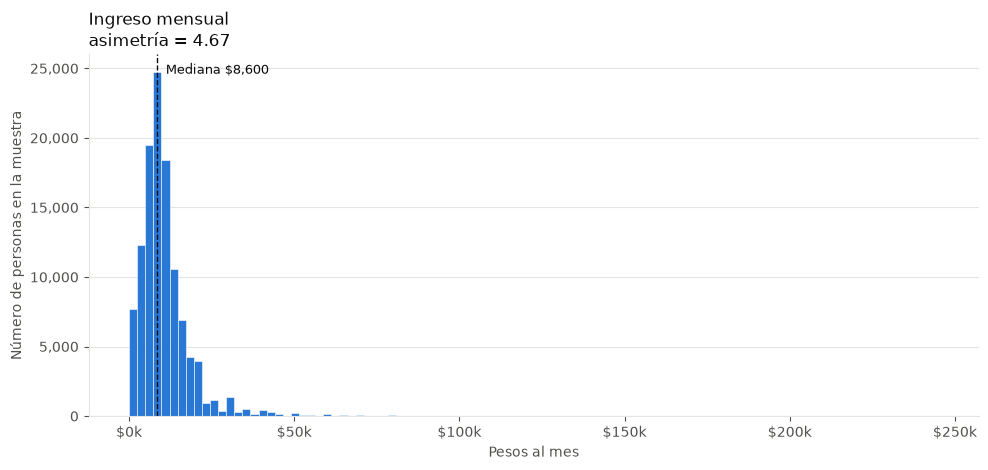

In [18]:
import matplotlib.pyplot as plt

# Colores
azul, texto, texto_2, grid = '#2a78d6', '#0b0b0b', '#52514e', '#e4e3df'

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.hist(df['ingreso_mensual'], bins=100, color=azul, edgecolor='white', linewidth=0.4)

# Mediana como referencia
mediana = df['ingreso_mensual'].median()
ax.axvline(mediana, color=texto, linewidth=1, linestyle='--')
ax.annotate(f'Mediana ${mediana:,.0f}', xy=(mediana, 1), xycoords=('data', 'axes fraction'),
            xytext=(6, -14), textcoords='offset points', color=texto, fontsize=9)

ax.set_title(f"Ingreso mensual\nasimetría = {df['ingreso_mensual'].skew():.2f}", loc='left', color=texto, fontsize=12)
ax.set_xlabel('Pesos al mes', color=texto_2)
ax.set_ylabel('Número de personas en la muestra', color=texto_2)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x / 1000:,.0f}k'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:,.0f}'))
ax.grid(axis='y', color=grid, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=texto_2)
for lado in ['top', 'right']:
    ax.spines[lado].set_visible(False)
for lado in ['left', 'bottom']:
    ax.spines[lado].set_color(grid)

plt.tight_layout()
plt.show()

### <font color='navy'> Parte 3. Variables explicativas

#### Paso 1. Solo trabajadores subordinados con pago (`p3h`)

Las preguntas de sindicato (3i), contrato (3j) y prestaciones (3l y 3m) **solo se les hacen a los trabajadores subordinados**, es decir, a quienes tienen un jefe. A quienes trabajan por su cuenta el cuestionario se las salta, y tampoco tienen tamaño de empresa (`p3q`). Además, es difícil medir el salario de alguien que es su propio jefe.

La pregunta 3h (*"¿En este trabajo ... recibe un pago?"*) solo la contestan los subordinados, y `p3h = 1` significa que reciben un pago. Por eso nos quedamos únicamente con los registros con `p3h = 1`; los independientes quedan fuera porque no tienen respuesta en esta pregunta.

In [19]:
# Solo trabajadores subordinados que reciben un pago
df = df[df['p3h'] == 1]
print('Subordinados con pago:', len(df))

Subordinados con pago: 87744


#### Paso 2. Sindicato (`p3i`), contrato (`p3j`) y tamaño de empresa (`p3q`)

+ **Sindicato:** 1 = pertenece a un sindicato, 0 = no.
+ **Contrato:** 1 = tiene contrato por escrito (temporal o de base), 0 = no.
+ **Tamaño de empresa:** ordinal de 1 (1 persona) a 11 (501 y más personas). El modelo la tratará como numérica, es decir, asume la misma distancia entre categorías consecutivas.

Eliminamos los "no sabe": 9 en `p3i` y `p3j`, y 99 en `p3q`.

In [20]:
# Quitar "no sabe": 9 en sindicato y contrato, 99 en tamaño de empresa
df = df[(df['p3i'] != 9) & (df['p3j'] != 9) & (df['p3q'] != 99)]

# Binarias: 1 = sí, 0 = no
df = df.assign(sindicato=(df['p3i'] == 1).astype(int),
               contrato=(df['p3j'] == 1).astype(int),
               tamano_empresa=df['p3q'].astype(int))

print('Sin "no sabe" en sindicato, contrato y tamaño:', len(df))
df[['sindicato', 'contrato']].mean().round(3)

Sin "no sabe" en sindicato, contrato y tamaño: 80837


/var/folders/8p/4mr53c2n1p78c15lqfqh7jww0000gn/T/ipykernel_67778/1525385143.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df = df.assign(sindicato=(df['p3i'] == 1).astype(int),


sindicato    0.155
contrato     0.544
dtype: float64

#### Paso 3. Prestaciones (`p3m1` a `p3m9`)

La pregunta 3m es de respuesta múltiple: cada opción (crédito de vivienda, guardería, cuidados maternos/paternos, fondo de retiro, seguro de vida, gastos médicos, préstamos) es una columna. Por simplicidad la reducimos a una **binaria**: si tiene al menos una prestación o no, sin importar cuántas tenga.

Hay que cuidar los vacíos: cuando a la persona **no le dan nada** en la pregunta anterior (3l: ni aguinaldo, ni vacaciones, ni utilidades, `p3l5`), el cuestionario se salta la 3m. Esos vacíos no son "no sabe", sino personas sin prestaciones, así que valen **0**. Solo eliminamos los "no sabe" (`p3m9` o `p3l9`).

In [21]:
# Quitar "no sabe" (p3m9 o p3l9)
df = df[df['p3m9'].isna() & df['p3l9'].isna()]

# 1 si marcó al menos una prestación de 3m (opciones 1 a 7);
# 0 si marcó "ninguna de las anteriores" (p3m8) o "no le dan nada" en 3l (p3l5)
df = df.assign(prestaciones=df[[f'p3m{i}' for i in range(1, 8)]].notna().any(axis=1).astype(int))

print('Sin "no sabe" en prestaciones:', len(df))
df['prestaciones'].value_counts()

Sin "no sabe" en prestaciones: 80100


/var/folders/8p/4mr53c2n1p78c15lqfqh7jww0000gn/T/ipykernel_67778/4221767360.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df = df.assign(prestaciones=df[[f'p3m{i}' for i in range(1, 8)]].notna().any(axis=1).astype(int))


prestaciones
1    42019
0    38081
Name: count, dtype: int64

#### Paso 4. Antigüedad (`p3r_anio`)

`p3r_anio` es el año en que la persona entró a trabajar por primera vez para su empresa actual. La antigüedad es `2025 − p3r_anio`. Si la persona se fue y regresó a la misma empresa, lo contamos igual como antigüedad en esa empresa.

+ Eliminamos los 9999 (no sabe).
+ Eliminamos las antigüedades imposibles, es decir, mayores que la edad menos 12 años (por ejemplo, alguien de 30 años con 25 de antigüedad).

In [22]:
# Año del levantamiento (per = 125 -> primer trimestre de 2025)
anio_encuesta = 2025

# Quitar "no sabe" (9999)
df = df[df['p3r_anio'] != 9999]
df = df.assign(antiguedad=anio_encuesta - df['p3r_anio'])

# Quitar antigüedades imposibles: habría entrado a la empresa antes de los 12 años
df = df[df['antiguedad'] <= df['eda'] - 12]

print('Con antigüedad válida:', len(df))
df['antiguedad'].describe().round(1)

Con antigüedad válida: 79426


/var/folders/8p/4mr53c2n1p78c15lqfqh7jww0000gn/T/ipykernel_67778/2819941191.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df = df.assign(antiguedad=anio_encuesta - df['p3r_anio'])


count    79426.0
mean         7.0
std          8.2
min          0.0
25%          2.0
50%          4.0
75%          9.0
max         68.0
Name: antiguedad, dtype: float64

#### Paso 5. Horas trabajadas a la semana (`p5c_thrs`, `p5e_thrs`)

La pregunta 5c registra las horas trabajadas **la semana pasada** (`p5c_thrs`). Después, la 5d pregunta si ese es su horario habitual; solo si contesta que no, la 5e registra las horas que trabaja **habitualmente** (`p5e_thrs`). Por eso:

+ Si `p5e_thrs` tiene dato, usamos las horas habituales.
+ Si no, usamos `p5c_thrs`: o la semana pasada fue su semana habitual, o la persona no tiene un horario regular y lo único que tenemos es lo que trabajó.

Eliminamos los registros sin ninguno de los dos datos (personas ausentes la semana pasada y sin horario regular) y los que tienen 999 (no especificado).

In [23]:
# Horas habituales si las dio (p5e_thrs); si no, las de la semana pasada (p5c_thrs)
df = df.assign(horas_semana=df['p5e_thrs'].fillna(df['p5c_thrs']))

# Quitar sin dato y "no especificado" (999)
df = df[df['horas_semana'].notna() & (df['horas_semana'] != 999)]

print('Con horas a la semana válidas:', len(df))
df['horas_semana'].describe().round(1)

Con horas a la semana válidas: 78944


/var/folders/8p/4mr53c2n1p78c15lqfqh7jww0000gn/T/ipykernel_67778/731451548.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df = df.assign(horas_semana=df['p5e_thrs'].fillna(df['p5c_thrs']))


count    78944.0
mean        43.3
std         14.6
min          1.0
25%         39.0
50%         45.0
75%         48.0
max        140.0
Name: horas_semana, dtype: float64

#### Paso 6. Horas de capacitación (`p11_h1`, `p11_m1`)

La pregunta 11 opción 1 registra cuánto tiempo dedicó la persona la semana pasada a *"estudiar o tomar cursos de capacitación (incluye el tiempo dedicado a realizar trabajos escolares)"*. Sumamos horas y minutos (`p11_h1 + p11_m1 / 60`).

+ Si está vacía, la persona no realizó esa actividad, así que le asignamos **0 horas**.
+ Los valores 98 y 99 se concentran en un pico sin minutos, por lo que los tratamos como no especificado y los eliminamos.

> **Nota:** la pregunta incluye estudiar en general, no solo capacitación para el trabajo. Quienes la reportan son sobre todo personas jóvenes que estudian y trabajan, así que el efecto sobre el ingreso podría no ser positivo.

In [24]:
# Quitar 98 y 99 (no especificado)
df = df[~df['p11_h1'].isin([98, 99])]

# Horas + minutos; vacío = no estudió ni tomó cursos -> 0 horas
df = df.assign(horas_capacitacion=(df['p11_h1'] + df['p11_m1'] / 60).fillna(0))

print('Con horas de capacitación válidas:', len(df))
print('Personas con más de 0 horas:      ', (df['horas_capacitacion'] > 0).sum())

Con horas de capacitación válidas: 78840
Personas con más de 0 horas:       6100


/var/folders/8p/4mr53c2n1p78c15lqfqh7jww0000gn/T/ipykernel_67778/298404567.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df = df.assign(horas_capacitacion=(df['p11_h1'] + df['p11_m1'] / 60).fillna(0))


#### Paso 7. Dataset para el modelo

Nos quedamos con la variable objetivo y las siete variables explicativas. También conservamos `fac_tri` para poder expresar resultados en millones de personas en el reporte; no entra en la regresión.

In [25]:
# Dataset para el modelo
columnas = ['ingreso_mensual', 'sindicato', 'contrato', 'tamano_empresa', 'prestaciones',
            'antiguedad', 'horas_semana', 'horas_capacitacion', 'fac_tri']
modelo = df[columnas]

print('Dataset del modelo:', modelo.shape)
modelo.describe().round(2).T

Dataset del modelo: (78840, 9)


,count,mean,std,min,25%,50%,75%,max
ingreso_mensual,78840.0,10748.88,7712.41,4.0,6450.0,9000.0,12900.0,238000.0
sindicato,78840.0,0.16,0.36,0.0,0.0,0.0,0.0,1.0
contrato,78840.0,0.55,0.50,0.0,0.0,1.0,1.0,1.0
tamano_empresa,78840.0,5.44,3.59,1.0,2.0,4.0,9.0,11.0
prestaciones,78840.0,0.53,0.50,0.0,0.0,1.0,1.0,1.0
antiguedad,78840.0,7.04,8.19,0.0,2.0,4.0,9.0,68.0
horas_semana,78840.0,43.34,14.61,1.0,39.0,45.0,48.0,140.0
horas_capacitacion,78840.0,1.28,6.06,0.0,0.0,0.0,0.0,90.0
fac_tri,78840.0,288.52,384.61,10.0,90.0,162.0,334.0,8183.0


### <font color='navy'> Parte 2. Aplicando modelo de Regresión Linear Múltiple.

### <font color='navy'> Parte 3. Analizando el summary del modelo.